In [7]:
import numpy as np
import pandas as pd
import itertools
import matplotlib.pyplot as plt
from datetime import date
import re
from tqdm import tqdm
import time
# from pybedtools import BedTool
import random
import math
import pickle
import seaborn as sns
from scipy.stats import percentileofscore, pearsonr, rankdata
from scipy.spatial.distance import jaccard, euclidean, cosine
import functools
import operator
import gzip
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import sys
import os
from functools import partial
from contextlib import closing
from multiprocessing import Pool
import re
import h5py

today = date.today()

**6/10/22 edits to step 2a**

In [2]:
num_cpus=1

In [4]:
#6/6/22

#find the cosine simliarity for 1 region compared to all regions in terms of region inds
def cosine_sim_regions_per_ind(ooe_arr, ind):
    cosine_sim_arr = cosine_similarity(ooe_arr[[ind], :], ooe_arr)[0]
    cosine_sim_arr[ind] = -1
    cosine_sim_inds_arr = (np.argsort(-cosine_sim_arr))[:1000]
    return cosine_sim_inds_arr

#find the cosine simliarity for 1 region compared to all regions
def cosine_sim_per_ind(ooe_arr, top_1000_similar_inds, ind):
    cosine_sim_arr = cosine_similarity(ooe_arr[[ind], :], ooe_arr[top_1000_similar_inds[ind], :])[0]
    return cosine_sim_arr

In [141]:
#load the data
print('Loading data...', flush=True)
ooe_path = '/home/ctrader/region_similarity/data/regions_100k_CT20220602.DHSoee.npy'
ooe_arr = np.load(ooe_path)

#split on cluster and calculate cosine similarity for all regions
print('Calculating cosine similarity...', flush=True)
func = partial(cosine_sim_regions_per_ind, ooe_arr)
with closing(Pool(num_cpus)) as pool:
    top_1000_similar_inds = pool.map(func, np.arange(111))
pool.join()
top_1000_similar_inds = np.array(top_1000_similar_inds)

print('values')
func = partial(cosine_sim_per_ind, ooe_arr, top_1000_similar_inds)
with closing(Pool(num_cpus)) as pool:
    top_1000_cosine_vals = pool.map(func, np.arange(111))
pool.join()
top_1000_cosine_vals = np.array(top_1000_cosine_vals)


top_1000_rank_vals = (1000 - (rankdata(-top_1000_cosine_vals, method='max', axis=1) - 1)) / 1000
top_1000_rank_vals = np.where(top_1000_cosine_vals!=0, top_1000_rank_vals, 0)

Loading data...
Calculating cosine similarity...
values


In [152]:
max_possible_val = 1
min_nonzero_val = np.min(top_1000_cosine_vals_full[top_1000_cosine_vals_full!=0])
top_1000_scaled_vals = (top_1000_cosine_vals_full - min_nonzero_val) / (max_possible_val - min_nonzero_val)
top_1000_scaled_vals[top_1000_scaled_vals<0] = 0

In [136]:
np.max(top_1000_cosine_vals_full)

0.9996961123519479

In [135]:
np.max(top_1000_scaled_vals)

0.999643545347838

In [129]:
top_1000_cosine_vals_full[top_1000_cosine_vals_full==0].shape

(5439000,)

In [107]:
max_possible_val = 220
test = np.array([110, 121, 125, 150, 180, 215])
# test
(test - np.min(test)) / (max_possible_val - np.min(test))

array([0.        , 0.1       , 0.13636364, 0.36363636, 0.63636364,
       0.95454545])

In [ ]:
# np.savez(cosine_path, top_1000_cosine_vals=top_1000_cosine_vals, top_1000_similar_regions=top_1000_similar_inds, top_1000_rank_vals=top_1000_rank_vals)

In [19]:
#trying hdf5 file
f = h5py.File('/home/ctrader/region_similarity/data/hdf5_test_CT20220610.hdf5', 'w')
dset = f.create_dataset('top_1000_rank_vals', data=top_1000_rank_vals)
dset = f.create_dataset('top_1000_similar_inds', data=top_1000_similar_inds)
dset = f.create_dataset('top_1000_cosine_vals', data=top_1000_cosine_vals)
f.close()
# dset = 

In [20]:
f_open = h5py.File('/home/ctrader/region_similarity/data/hdf5_test_CT20220610.hdf5', 'r')
list(f_open.keys())

['top_1000_cosine_vals', 'top_1000_rank_vals', 'top_1000_similar_inds']

In [48]:
f_open['top_1000_cosine_vals'].shape

(111, 1000)

In [143]:
top_1000_rank_vals_full = np.load('/home/ctrader/region_similarity/data/regions_100k_CT20220608.DHScosine.npz')['top_1000_rank_vals']
top_1000_cosine_vals_full = np.load('/home/ctrader/region_similarity/data/regions_100k_CT20220608.DHScosine.npz')['top_1000_cosine_vals']
top_1000_similar_inds_full = np.load('/home/ctrader/region_similarity/data/regions_100k_CT20220608.DHScosine.npz')['top_1000_similar_regions']

In [66]:
roi = 12345

In [67]:
t = time.time()
top_1000_rank_vals_roi = np.load('/home/ctrader/region_similarity/data/regions_100k_CT20220608.TFcosine.npz')['top_1000_rank_vals'][roi]
top_1000_similar_inds_roi = np.load('/home/ctrader/region_similarity/data/regions_100k_CT20220608.TFcosine.npz')['top_1000_similar_regions'][roi]
time.time()-t

2.1633048057556152

In [42]:
f = h5py.File('/home/ctrader/region_similarity/data/hdf5_test_full_arr_CT20220610.hdf5', 'w')
dset = f.create_dataset('top_1000_rank_vals', data=top_1000_rank_vals_full)
dset = f.create_dataset('top_1000_similar_inds', data=top_1000_similar_inds_full)
dset = f.create_dataset('top_1000_cosine_vals', data=top_1000_cosine_vals_full)
f.close()

In [82]:
t = time.time()
f_full_open = h5py.File('/home/ctrader/region_similarity/data/hdf5_test_full_arr_CT20220610.hdf5', 'r')
top_1000_rank_vals_hdf5_roi = f_full_open['top_1000_rank_vals'][roi]
top_1000_similar_inds_hdf5_roi = f_full_open['top_1000_similar_inds'][roi]
time.time()-t

0.0031549930572509766

In [84]:
t = time.time()
x = f_full_open['top_1000_rank_vals'][:, :]
time.time() - t

0.2832779884338379

In [75]:
f_full_open.close()

**6/6/22, combining scores**

In [11]:
#load the data
print('Loading data...', flush=True)
ooe_path = '/home/ctrader/region_similarity/data/regions_100k_CT20220602.DHSoee.npy'
ooe_arr = np.load(ooe_path)

#split on cluster and calculate cosine similarity for all regions
print('Calculating cosine similarity...', flush=True)
# func1 = partial(cosine_sim_per_ind, ooe_arr)
func = partial(cosine_sim_regions_per_ind, ooe_arr)
with closing(Pool(num_cpus)) as pool:
#     top_100_cosine_valsDHS = pool.map(func1, np.arange(111))
    top_100_similar_indsDHS = pool.map(func, np.arange(111))
pool.join()
# top_100_cosine_valsDHS = np.array(top_100_cosine_valsDHS)
top_100_similar_indsDHS = np.array(top_100_similar_indsDHS)



# top_100_rank_valsDHS = (len(ooe_arr) - (rankdata(-top_100_cosine_valsDHS, method='max', axis=1) - 1)) / len(ooe_arr)
# top_100_rank_valsDHS = np.where(top_100_cosine_valsDHS!=0, top_100_rank_valsDHS, 0)

Loading data...
Calculating cosine similarity...


In [6]:
#load the data
print('Loading data...', flush=True)
ooe_path = '/home/ctrader/region_similarity/data/regions_100k_CT20220602.TFoee.npy'
ooe_arr = np.load(ooe_path)

#split on cluster and calculate cosine similarity for all regions
print('Calculating cosine similarity...', flush=True)
func1 = partial(cosine_sim_per_ind, ooe_arr)
func2 = partial(cosine_sim_regions_per_ind, ooe_arr)
with closing(Pool(num_cpus)) as pool:
#     top_100_cosine_vals = pool.map(func1, np.arange(len(ooe_arr)))
#     top_100_similar_inds = pool.map(func2, np.arange(len(ooe_arr)))
    top_100_cosine_valsTF = pool.map(func1, np.arange(111))
    top_100_similar_indsTF = pool.map(func2, np.arange(111))
pool.join()
top_100_cosine_valsTF = np.array(top_100_cosine_valsTF)
top_100_similar_indsTF = np.array(top_100_similar_indsTF)

top_100_rank_valsTF = (len(ooe_arr) - (rankdata(-top_100_cosine_valsTF, method='max', axis=1) - 1)) / len(ooe_arr)
top_100_rank_valsTF = np.where(top_100_cosine_valsTF!=0, top_100_rank_valsTF, 0)

Loading data...
Calculating cosine similarity...


In [11]:
region = 0

region_DHS_arr = np.zeros(len(ooe_arr))#change to len(top_100_similar_indsDHS) for full script so we don't have to load ooe_arr
region_DHS_arr[top_100_similar_indsDHS[region, :]] = top_100_rank_valsDHS[region, :]/100
region_TF_arr = np.zeros(len(ooe_arr))
region_TF_arr[top_100_similar_indsTF[region, :]] = top_100_rank_valsTF[region, :]/100

result = 1 - ((1 - region_TF_arr) * (1 - region_DHS_arr))
resulting_scores = np.append(1, -np.sort(-result)[:100])
resulting_regions = np.argsort(-result0)[:100]
# count_data0 = count_data[region, :3]
# count_data0 = np.vstack((count_data0, count_data[resulting0_regions, :3]))

In [2]:
t = np.zeros(9999)

In [4]:
t[9999]

IndexError: index 9999 is out of bounds for axis 0 with size 9999

In [107]:
f = open('/home/ctrader/region_similarity/data/Altius_100k_epilogos_hg19_WM20210518.sorted.bed', 'r')
regions = []
for line in f:
    regions.append(line.strip().split('\t'))
f.close()
regions = np.array(regions)

In [137]:
genome_coords = 'chr16:9000-9001'

chrm = genome_coords.split(':')[0]
start = int(genome_coords.split(':')[1].split('-')[0])
end = int(genome_coords.split(':')[1].split('-')[1])

region_ind = np.where((regions[:, 0]==chrm) & 
                      (regions[:, 1].astype(int)<=start) & 
                      (regions[:, 2].astype(int)>=end))[0]


if len(region_ind)!=1:
    sys.exit('Region not found')
else:
    f = open('/home/ctrader/region_similarity/data/test_CT20220606.txt', 'w')
    f.write(str(region_ind[0]))
    f.close

In [138]:
region_ind[0]

32432

In [119]:
regions[:, 1].astype(int)

array([     9000,     34000,     61000, ..., 155092800, 155117800,
       155142800])

In [140]:
f = open('/home/ctrader/region_similarity/data/region_of_interest_CT20220606.txt', 'r')
roi = int(f.readline())

In [141]:
roi

32432

In [25]:
#find the cosine simliarity for 1 region compared to all regions
def cosine_sim_per_ind(ooe_arr, sample_inds, tmp_path, ind):
    cosine_sim_arr = cosine_similarity(ooe_arr[[ind], :], ooe_arr)[0]
    if ind in sample_inds:
        np.save(os.path.join(tmp_path, 'sample_'+str(ind)+'_test_cosine_arr.npy'), cosine_sim_arr)
    cosine_sim_arr[ind] = -1######move to here
    cosine_sim_arr = (-np.sort(-cosine_sim_arr))[:100]
    return cosine_sim_arr

In [26]:
#find the cosine simliarity for 1 region compared to all regions in terms of region inds
def cosine_sim_regions_per_ind(ooe_arr, sample_inds, tmp_path, ind):
    cosine_sim_arr = cosine_similarity(ooe_arr[[ind], :], ooe_arr)[0]
    cosine_sim_arr[ind] = -1#####
    cosine_sim_inds_arr = (np.argsort(-cosine_sim_arr))[:100]
    return cosine_sim_inds_arr

In [27]:
#find the percentiles of top 100 cosine values for each region
def percentile_calc(cosine_samples, sample_top_cosine):
    #sample_top_cosine = top_100_cosine_vals[ind, :]
    sample_percentiles = []
    for score in sample_top_cosine:
        sample_percentiles.append(percentileofscore(cosine_samples, score))
    return sample_percentiles

In [37]:
#load the data
print('Loading data...', flush=True)

ooe_path = '/home/ctrader/region_similarity/data/regions_100k_CT20220602.DHSoee.npy'
ooe_arr = np.load(ooe_path)

sample_inds = np.array(random.sample(range(110), k=10))

#split on cluster and calculate cosine similarity for all regions
print('Calculating cosine similarity...', flush=True)
tmp_path = '/home/ctrader/region_similarity/data/DHS_tmp_files'
func1 = partial(cosine_sim_per_ind, ooe_arr, sample_inds, tmp_path)
func2 = partial(cosine_sim_regions_per_ind, ooe_arr, sample_inds, tmp_path)
with closing(Pool(1)) as pool:
    top_100_cosine_vals_DHS = pool.map(func1, np.arange(110))
    top_100_similar_inds_DHS = pool.map(func2, np.arange(110))
pool.join()
top_100_cosine_vals_DHS = np.array(top_100_cosine_vals_DHS)
top_100_similar_inds_DHS = np.array(top_100_similar_inds_DHS)

#sample 100 regions in order to calculate percentiles
print('Sampling...')
#sample_inds = np.array(random.sample(range(len(ooe_arr)), k=100))

cosine_samples = np.array([])
for i in sample_inds:
    cosine_samples = np.append(cosine_samples, np.load(os.path.join(tmp_path, 'sample_'+str(i)+'_test_cosine_arr.npy')))

print('Calculating percentiles...', flush=True)
func3 = partial(percentile_calc, cosine_samples)
with closing(Pool(1)) as pool:
    top_100_percentiles_DHS = pool.map(func3, top_100_cosine_vals_DHS[np.arange(110), :])
pool.join()
top_100_percentiles_DHS = np.array(top_100_percentiles_DHS)

Loading data...
Calculating cosine similarity...
Sampling...
Calculating percentiles...


In [36]:
#load the data
print('Loading data...', flush=True)

ooe_path = '/home/ctrader/region_similarity/data/regions_100k_CT20220602.TFoee.npy'
ooe_arr = np.load(ooe_path)

sample_inds = np.array(random.sample(range(110), k=10))

#split on cluster and calculate cosine similarity for all regions
print('Calculating cosine similarity...', flush=True)
tmp_path = '/home/ctrader/region_similarity/data/TF_tmp_files'
func1 = partial(cosine_sim_per_ind, ooe_arr, sample_inds, tmp_path)
func2 = partial(cosine_sim_regions_per_ind, ooe_arr, sample_inds, tmp_path)
with closing(Pool(1)) as pool:
    top_100_cosine_vals_TF = pool.map(func1, np.arange(110))
    top_100_similar_inds_TF = pool.map(func2, np.arange(110))
pool.join()
top_100_cosine_vals_TF = np.array(top_100_cosine_vals_TF)
top_100_similar_inds_TF = np.array(top_100_similar_inds_TF)

#sample 100 regions in order to calculate percentiles
print('Sampling...')
#sample_inds = np.array(random.sample(range(len(ooe_arr)), k=100))

cosine_samples = np.array([])
for i in sample_inds:
    cosine_samples = np.append(cosine_samples, np.load(os.path.join(tmp_path, 'sample_'+str(i)+'_test_cosine_arr.npy')))

print('Calculating percentiles...', flush=True)
func3 = partial(percentile_calc, cosine_samples)
with closing(Pool(1)) as pool:
    top_100_percentiles_TF = pool.map(func3, top_100_cosine_vals_TF[np.arange(110), :])
pool.join()
top_100_percentiles_TF = np.array(top_100_percentiles_TF)

Loading data...
Calculating cosine similarity...
Sampling...
Calculating percentiles...


In [117]:
region = 0

region0_DHS_arr = np.zeros(99996)
region0_DHS_arr[top_100_similar_inds_DHS[region, :]] = top_100_percentiles_DHS[region, :]/100
region0_TF_arr = np.zeros(99996)
region0_TF_arr[top_100_similar_inds_TF[region, :]] = top_100_percentiles_TF[region, :]/100

result0 = 1 - ((1 - region0_TF_arr) * (1 - region0_DHS_arr))
resulting0_scores = np.append(1, -np.sort(-result0)[:100])
resulting0_regions = np.argsort(-result0)[:100]
count_data0 = count_data[region, :3]
count_data0 = np.vstack((count_data0, count_data[resulting0_regions, :3]))

In [118]:
bed_path_name = os.path.join('/home/ctrader/public_html/', 'test_region0_top100_similar_regions_CT' + today.strftime("%Y%m%d") + '.bed')
f= open(bed_path_name, 'w')
for i in range(100):
    f.write(count_data0[i, 0] + '\t' + str(count_data0[i, 1]) + '\t' + str(count_data0[i, 2]) + '\t' + str(resulting0_scores[i]) + '\n')
f.close()
link_path = 'https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2F' + 'test_region0_top100_similar_regions_CT' + today.strftime("%Y%m%d") + '.bed'
print(link_path)

https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2Ftest_region0_top100_similar_regions_CT20220603.bed


In [123]:
print('https://epilogos.altius.org:3001/?application=viewer&sampleSet=vA&mode=single&genome=hg19&model=15&complexity=KL&group=all&chrLeft=chr1&chrRight=chr1&start=8000&stop=35000&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2Ftest_region0_top100_similar_regions_CT20220603.bed')

https://epilogos.altius.org:3001/?application=viewer&sampleSet=vA&mode=single&genome=hg19&model=15&complexity=KL&group=all&chrLeft=chr1&chrRight=chr1&start=8000&stop=35000&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2Ftest_region0_top100_similar_regions_CT20220603.bed


In [124]:
print('https://epilogos.altius.org:3001/?application=viewer&sampleSet=vA&mode=single&genome=hg19&model=15&complexity=KL&group=all&chrLeft=chr1&chrRight=chr1&start=8000&stop=35000&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2Ftest_region50_top100_similar_regions_CT20220603.bed')

https://epilogos.altius.org:3001/?application=viewer&sampleSet=vA&mode=single&genome=hg19&model=15&complexity=KL&group=all&chrLeft=chr1&chrRight=chr1&start=8000&stop=35000&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2Ftest_region50_top100_similar_regions_CT20220603.bed


In [125]:
print('https://epilogos.altius.org:3001/?application=viewer&sampleSet=vA&mode=single&genome=hg19&model=15&complexity=KL&group=all&chrLeft=chr1&chrRight=chr1&start=8000&stop=35000&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2Ftest_region90_top100_similar_regions_CT20220603.bed')

https://epilogos.altius.org:3001/?application=viewer&sampleSet=vA&mode=single&genome=hg19&model=15&complexity=KL&group=all&chrLeft=chr1&chrRight=chr1&start=8000&stop=35000&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2Ftest_region90_top100_similar_regions_CT20220603.bed


In [2]:
ooe_arr = np.load('/home/ctrader/region_similarity/data/regions_100k_CT20220602.DHSoee.npy')

In [3]:
def cosine_sim_per_ind(ooe_arr, ind):
    cosine_sim_arr = cosine_similarity(ooe_arr[[ind], :], ooe_arr)[0]
    return cosine_sim_arr

In [4]:
def percentile_calc(cosine_samples, top_100_cosine_vals, ind):
    sample_top_cosine = top_100_cosine_vals[ind, :]
    sample_percentiles = []
    for score in sample_top_cosine:
        sample_percentiles.append(percentileofscore(cosine_samples, score))
    return sample_percentiles

In [54]:
func1 = partial(cosine_sim_per_ind, ooe_arr)
with closing(Pool(1)) as pool:
    cosine_m = pool.map(func1, np.arange(110))
pool.join()

cosine_m = np.array(cosine_m)

In [91]:
cosine_m = cosine_m[1:, :]
cosine_m.shape

(0, 99996)

In [45]:
sample_inds = np.array(random.sample(range(110), k=10))
# sample_inds = np.array(random.sample(range(len(ooe_arr)), k=100))
cosine_samples = np.ndarray.flatten(cosine_m[sample_inds, :])

In [43]:
cosine_m[np.arange(110), np.arange(110)] = -1

top_100_cosine_vals = []
top_100_similar_inds = []

while len(cosine_m) > 0:
    row = cosine_m[0, :]
    top_100_cosine_vals.append((-np.sort(-row))[:100])
    top_100_similar_inds.append((np.argsort(-row))[:100])
    cosine_m = cosine_m[1:, :]
    
top_100_cosine_vals = np.array(top_100_cosine_vals)
top_100_similar_inds = np.array(top_100_similar_inds)

In [71]:
np.max(top_100_similar_inds - top_100_simlar_indstest)

0.0

In [47]:
# # cosine_m[np.arange(len(ooe_arr)), np.arange(len(ooe_arr))] = -1
# cosine_m[np.arange(110), np.arange(110)] = -1

# cosine_m[np.arange(110), np.arange(110)] = -1

# top_100_cosine_valstest = -np.sort(-cosine_m, axis=1)[:, :100]
# top_100_simlar_indstest = np.argsort(-cosine_m, axis=1)[:, :100]
# del cosine_m

In [78]:
func2 = partial(percentile_calc, cosine_samples, top_100_cosine_vals)
with closing(Pool(1)) as pool:
    top_100_percentiles = pool.map(func2, np.arange(110))
pool.join()

top_100_percentiles = np.array(top_100_percentiles)

In [146]:
#load count data
filename = '/home/ctrader/region_similarity/data/regions_100k_CT20220602.DHSmapped.bed'
count_data = []
f = open(filename, 'r')
for line in f:
    count_data.append(line.strip().split('\t'))
f.close()
count_data = np.array(count_data)

In [156]:
# seperating count labels and count values
count_data_vals = count_data[1:, 3:].astype(int)

In [163]:
#finding the total number of counts for each label
total_counts = np.sum(count_data_vals, axis=0)

In [160]:
# #finding the total number of counts for each label
# dir_path = '/home/ctrader/region_similarity/data/tf_motif_bed'
# total_counts = np.array([], dtype=int)
# for label in count_data_labels:
#     label_path = os.path.join(dir_path, label+'.bed')
#     f = open(label_path, 'r')
#     total_counts = np.append(total_counts, len(f.readlines()))

In [165]:
#finding observed over expected for each label
# expected = total_counts / len(count_data_vals)
# expected = total_counts / (3000000000/25000)
expected = total_counts / np.sum(total_counts)
observed = (count_data_vals.T / np.sum(count_data_vals, axis=1)).T
observed = np.where(np.isnan(observed), 0, observed)
ooe = observed / expected

/tmp/ipykernel_187857/2346344871.py:5: RuntimeWarning: invalid value encountered in true_divide
  observed = (count_data_vals.T / np.sum(count_data_vals, axis=1)).T


In [174]:
ooe[0]

array([ 0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        , 22.82248167,
        0.        ])

In [110]:
np.sum(observed[3])

1.0

In [184]:
#load score data
filename = '/home/ctrader/region_similarity/data/regions_100k_CT20220602.epilogosmapped.bed'
score_data = []
f = open(filename, 'r')
next(f)
for line in f:
    score_data.append(re.split('\t|\|', line.strip()))
f.close()
score_data = np.array(score_data)

In [202]:
score_data[0] #label, mean, max

array(['chr1', '9000', '34000', '0.000000', '0.000000', '-0.000082',
       '0.000000', '0.000000', '0.000000', '-0.000005', '0.000000',
       '0.000000', '0.000000', '-0.000187', '0.000000', '-0.001482',
       '0.000000', '0.393503', '0.410000', '-0.000032', '0.000000',
       '-0.000251', '0.000000', '0.000000', '0.000000', '0.000231',
       '0.016430', '0.000156', '0.012880', '0.000016', '0.002109',
       '0.000000', '0.000000', '-0.000124', '0.000000', '-0.013738',
       '0.000000', '-0.000104', '0.000685'], dtype='<U9')

In [128]:
# # seperating score labels and score values
# score_data_mean_vals = score_data[:, score_val_inds+1].astype(float)
# score_data_max_vals = score_data[:, score_val_inds+2].astype(float)

In [204]:
# seperating score labels and score values
score_data_mean_vals = score_data[:, 3::2].astype(float)
score_data_max_vals = score_data[:, 4::2].astype(float)

In [156]:
# #finding the total sum and max of scores for each label
# dir_path = '/home/ctrader/region_similarity/data/epilogos_component_bed'
# total_score_sum = np.array([], dtype=int)
# total_score_max = np.array([], dtype=int)
# for label in score_data_labels:
#     label_path = os.path.join(dir_path, label+'.bed')
#     label_data = np.array(pd.read_csv(label_path, sep='\t', usecols=[4], header=None, squeeze=True))
#     total_score_sum = np.append(total_score_sum, np.sum(label_data))
#     total_score_max = np.append(total_score_max, np.max(label_data))

In [213]:
#finding the average mean and max of scores for each label
expected_mean = np.mean(score_data_mean_vals, axis=0)
expected_max = np.mean(score_data_max_vals, axis=0)

In [163]:
# #finding ooe for score sums
# expected_sum = total_score_sum / np.sum(total_score_sum)
# observed_sum = (score_data_sum_vals.T / np.sum(score_data_sum_vals, axis=1)).T
# observed_sum = np.where(np.isnan(observed_sum), 0, observed_sum)
# ooe_sum = observed_sum / expected_sum

In [174]:
# #finding ooe for score max
# expected_max = total_score_max / np.max(total_score_max)
# observed_max = (score_data_max_vals.T / np.max(score_data_max_vals, axis=1)).T
# observed_max = np.where(np.isnan(observed_max), 0, observed_max)
# ooe_max = observed_max / expected_max

In [220]:
#finding ooe for score mean and max
ooe_mean = score_data_mean_vals / expected_mean
ooe_max = score_data_max_vals / expected_max

In [221]:
#combining sum and max
ooe = np.hstack((ooe_mean, ooe_max))

In [87]:
epilogos_ooe[1212]

array([ 2.68897196e+01,  1.16146563e+01,  0.00000000e+00,  1.41672647e+01,
        1.10331476e+01,  1.26498037e+01,  0.00000000e+00, -1.38532488e+00,
       -0.00000000e+00, -1.65424417e-02,  2.39858468e+00,  0.00000000e+00,
        2.73368919e-01,  2.57118329e+00,  1.37954310e+01,  1.64546376e+00,
        7.76410869e+00,  0.00000000e+00,  1.45300462e+01,  7.64866771e+00,
        0.00000000e+00,  1.45269782e+01,  1.25401723e+01,  9.48989002e+00,
        0.00000000e+00,  0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
        8.54061528e+00,  0.00000000e+00,  4.02308922e-01,  5.95156850e+00,
        1.21114891e+01,  5.30781001e+00,  6.80606476e+00,  0.00000000e+00])

In [71]:
epilogos_ooe = np.load('/home/ctrader/region_similarity/data/regions_100k_CT20220608.epilogosoee.npy')
epilogos_cosine = np.load(epilogos_npz_path)['top_1000_cosine_vals']
epilogos_rank = np.load(epilogos_npz_path)['top_1000_rank_vals']
epilogos_regions = np.load(epilogos_npz_path)['top_1000_similar_regions']

In [206]:
t = time.time()
roi = 72345

In [207]:
epilogos_npz_path = '/home/ctrader/region_similarity/data/regions_100k_CT20220608.epilogoscosine.npz'
epilogos_score_rank_vals = np.load(epilogos_npz_path)['top_1000_rank_vals'][roi]
epilogos_score_similar_regions = np.load(epilogos_npz_path)['top_1000_similar_regions'][roi]

In [208]:
DHS_npz_path = '/home/ctrader/region_similarity/data/regions_100k_CT20220608.DHScosine.npz'
DHS_count_rank_vals = np.load(DHS_npz_path)['top_1000_rank_vals'][roi]
DHS_count_similar_regions = np.load(DHS_npz_path)['top_1000_similar_regions'][roi]

In [209]:
TF_npz_path = '/home/ctrader/region_similarity/data/regions_100k_CT20220608.TFcosine.npz'
TF_count_rank_vals = np.load(TF_npz_path)['top_1000_rank_vals'][roi]
TF_count_similar_regions = np.load(TF_npz_path)['top_1000_similar_regions'][roi]

In [210]:
max_ind = np.max([epilogos_score_similar_regions, DHS_count_similar_regions])

In [211]:
DHS_arr = np.zeros(max_ind + 1)
DHS_arr[DHS_count_similar_regions] = DHS_count_rank_vals

In [212]:
epilogos_arr = np.zeros(max_ind + 1)
epilogos_arr[epilogos_score_similar_regions] = epilogos_score_rank_vals

In [213]:
TF_arr = np.zeros(max_ind + 1)
TF_arr[TF_count_similar_regions] = TF_count_rank_vals

In [214]:
score_arr = 1 - ((1 - epilogos_arr) * (1 - DHS_arr) * (1 - TF_arr))

In [215]:
#finding regions
top_region_inds = np.append(roi, np.argsort(-score_arr)[:100])
top_region_scores = np.append(1, -np.sort(-score_arr)[:100])

In [216]:
#find genomic locations
filename = '/home/ctrader/region_similarity/data/Altius_100k_epilogos_hg19_WM20210518.sorted.c1t3.bed'
f = open(filename, 'r')
regions = f.readlines()
top_regions = []
for ind in top_region_inds:
    top_regions.append(regions[ind].strip().split())
top_regions = np.array(top_regions)
f.close()

top_regions = np.hstack((top_regions, top_region_scores.reshape((len(top_region_scores), 1))))

In [217]:
roi_url_name = 'region_comparison_recommended_regions_roi_'+str(roi)+'_scale_250kb_CT' + today.strftime("%Y%m%d") + '.bed'
bed_path_name = os.path.join('/home/ctrader/public_html/', roi_url_name)
np.savetxt(bed_path_name, top_regions, delimiter='\t', fmt='%s')
link_path = 'https://epilogos.altius.org:3001/?application=viewer&sampleSet=vA&mode=single&genome=hg19&model=15&complexity=KL&group=all&chrLeft=chr1&chrRight=chr1&start=8000&stop=35000&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2F' + roi_url_name
print(link_path)
print(time.time()-t)

https://epilogos.altius.org:3001/?application=viewer&sampleSet=vA&mode=single&genome=hg19&model=15&complexity=KL&group=all&chrLeft=chr1&chrRight=chr1&start=8000&stop=35000&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2Fregion_comparison_recommended_regions_roi_72345_scale_250kb_CT20220609.bed
73.86703538894653


In [100]:
print(np.argsort(-score_arr)[:100])
print(-np.sort(-score_arr)[:100])
print()
print(epilogos_arr[np.argsort(-score_arr)[:100]])
print(DHS_arr[np.argsort(-score_arr)[:100]])
print()
print(epilogos_arr[np.argsort(-score_arr)[:100]]+DHS_arr[np.argsort(-score_arr)[:100]])

[35219 38135 96595 73813    77 66012 14850 35365 57624 37940 35089 13705
 32774 16792 52174 91385  9148 12562 62935 22675 14535 94960 94821 98139
  9246 16488 54063 51228 98580 35988 19078  3185 76190 49458 78159 28907
  1033 98606  7890 36856 34374 95480 50250 12932 58198 16950 72693 73799
 38075  2711 98608 41973   606 52236 83084 55692 77389 86735 76193 43470
 88056 42568 55256  2941 14623   722 31672 43974 46607 49138 66399 59847
 46850 92824 62374 93559 49560 34789 49333 84562 69500 10845 20757 68715
 12499 25335 77603 20697 30162 80490 99266  5893  5507 52489 62779 22407
 25346 73453 90038  2139]
[1.      1.      0.999   0.999   0.998   0.998   0.997   0.997   0.99622
 0.996   0.996   0.995   0.995   0.994   0.994   0.993   0.993   0.992
 0.992   0.991   0.991   0.99    0.99    0.989   0.989   0.988   0.988
 0.987   0.987   0.986   0.986   0.985   0.985   0.984   0.984   0.983
 0.983   0.982   0.981   0.981   0.98    0.98    0.979   0.979   0.978
 0.978   0.977   0.977   0.976   

In [107]:
print(-np.sort(-(epilogos_arr + DHS_arr))[:100])
print()
print(epilogos_arr[np.argsort(-(epilogos_arr + DHS_arr))[:100]])
print(DHS_arr[np.argsort(-(epilogos_arr + DHS_arr))[:100]])

[1.772 1.591 1.27  1.159 1.105 1.002 1.    1.    0.999 0.999 0.998 0.998
 0.997 0.997 0.996 0.996 0.995 0.995 0.994 0.994 0.993 0.993 0.992 0.992
 0.991 0.991 0.99  0.99  0.989 0.989 0.988 0.988 0.987 0.987 0.986 0.986
 0.985 0.985 0.984 0.984 0.984 0.983 0.983 0.982 0.981 0.981 0.98  0.98
 0.979 0.979 0.978 0.978 0.977 0.977 0.976 0.976 0.975 0.975 0.974 0.974
 0.973 0.973 0.972 0.972 0.971 0.971 0.97  0.97  0.969 0.969 0.968 0.968
 0.967 0.967 0.966 0.966 0.965 0.965 0.964 0.964 0.963 0.963 0.962 0.962
 0.961 0.961 0.96  0.96  0.959 0.959 0.958 0.958 0.957 0.957 0.956 0.956
 0.955 0.955 0.954 0.954]

[0.982 0.825 0.897 0.746 0.427 0.3   1.    0.    0.    0.999 0.998 0.
 0.    0.997 0.    0.996 0.    0.995 0.994 0.    0.    0.993 0.992 0.
 0.991 0.    0.    0.99  0.989 0.    0.988 0.    0.    0.987 0.    0.986
 0.985 0.    0.701 0.    0.984 0.    0.983 0.    0.981 0.    0.    0.98
 0.979 0.    0.    0.978 0.    0.977 0.976 0.    0.975 0.    0.974 0.
 0.    0.973 0.972 0.    0.    0.97

In [ ]:
result0 = 1 - ((1 - region0_TF_arr) * (1 - region0_DHS_arr))
resulting0_scores = np.append(1, -np.sort(-result0)[:100])
resulting0_regions = np.argsort(-result0)[:100]
count_data0 = count_data[region, :3]
count_data0 = np.vstack((count_data0, count_data[resulting0_regions, :3]))

In [226]:
x = np.zeros((100, 100))
for i in np.arange(0, 1, 0.01):
    for j in np.arange(0, 1, 0.01):
        x[int(i*100), int(j*100)] = 1 - ((1 - i)*(1-j))

<AxesSubplot:>

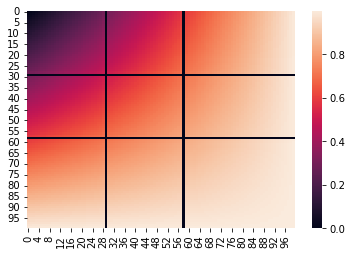

In [227]:
fig = plt.figure()

sns.heatmap(x)